In [3]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.stats import gaussian_kde


In [1]:
results_overfit = np.load('/home/ihor/projects/MLGuessQC/dxtb_experiments/results_ml_guess_eSCN/scf_iterations_mlguess_broyden0p2_eSCN_tmQM_overfit.npz')
results_overfit

NameError: name 'np' is not defined

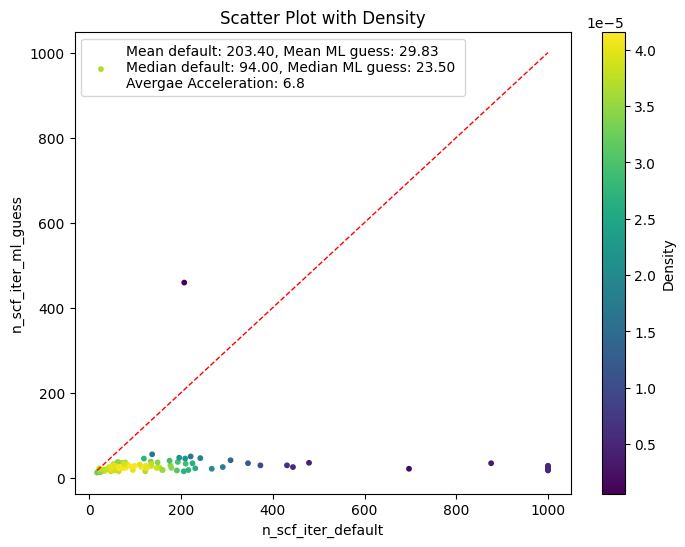

In [ ]:
n_scf_iter_default = results_overfit['n_scf_iter_default']
n_scf_iter_ml_guess = results_overfit['n_scf_iter_ml_guess']

n_scf_default_mean = np.mean(n_scf_iter_default)
n_scf_ml_guess_mean = np.mean(n_scf_iter_ml_guess)
n_scf_default_median = np.median(n_scf_iter_default)
n_scf_ml_guess_median = np.median(n_scf_iter_ml_guess)


xy = np.vstack([n_scf_iter_default.flatten(), n_scf_iter_ml_guess.flatten()])
z = gaussian_kde(xy)(xy)

average_acc = n_scf_default_mean/n_scf_ml_guess_mean

# Create the scatter plot
plt.figure(figsize=(8, 6))
plt.plot([min(n_scf_iter_default), max(n_scf_iter_default)], 
         [min(n_scf_iter_default), max(n_scf_iter_default)], 
         'r--', linewidth=1, zorder=2)
plt.scatter(n_scf_iter_default, n_scf_iter_ml_guess, c=z, s=10, cmap='viridis', 
            label="Mean default: {:.2f}, Mean ML guess: {:.2f} \nMedian default: {:.2f}, Median ML guess: {:.2f} \nAvergae Acceleration: {:.1f}".format(n_scf_default_mean, n_scf_ml_guess_mean, n_scf_default_median, n_scf_ml_guess_median, average_acc))
plt.legend()
plt.colorbar(label='Density')
plt.xlabel('n_scf_iter_default')
plt.ylabel('n_scf_iter_ml_guess')
plt.title('Scatter Plot with Density')
plt.show()

# tmQM Training MSE

In [ ]:
outputs = np.load('/home/ihor/projects/MLGuessQC/mlguess/results/TMQM_dxtb_charges_eSCN_K4L2_mse_loss/orbital_charges_epoch_43.npz')

In [ ]:
len(outputs['ground_truth']), len(outputs['predictions'])

(218425, 218425)

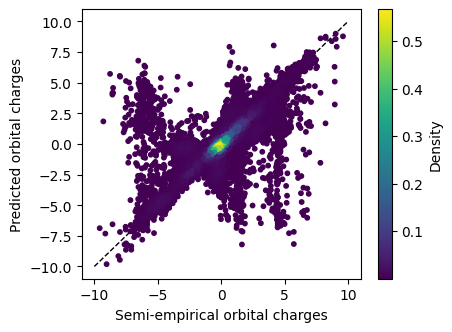

In [ ]:
from scipy.stats import gaussian_kde

# Extract data from the results
x = outputs['ground_truth'][:30000]
y = outputs['predictions'][:30000]

mse = np.mean((x - y) ** 2)
mae = np.mean(np.abs(x - y))

xy = np.vstack([x, y])
z = gaussian_kde(xy)(xy)

# Create the scatter plot
plt.figure(figsize=(4.5, 3.5))
plt.scatter(x, y, c=z, s=10, cmap='viridis', label=f"MSE: {mse:.5f}, MAE: {mae:.4f}")
plt.plot([-10, 10], [-10, 10], 'k--', linewidth=1, zorder=0)
plt.colorbar(label='Density')
plt.xlabel('Semi-empirical orbital charges')
plt.ylabel('Predicted orbital charges')
#plt.legend()
#plt.show()
plt.savefig('orbital_charges_scatter_density_lossMAE.png', dpi=300, bbox_inches='tight')

In [ ]:
orbital_map = np.load('/home/ihor/projects/MLGuessQC/dxtb_orbital_map.npz')

In [ ]:
atom_types_orbital = []
for atom_type in tqdm(outputs["atom_types"]):
    atom_types_orbital.extend([atom_type]*int(orbital_map[str(atom_type)]))


  3%|▎         | 1813/66718 [00:00<00:03, 18127.04it/s]

100%|██████████| 66718/66718 [00:03<00:00, 20527.89it/s]


Subplot for atom type: 1
Subplot for atom type: 5
Subplot for atom type: 6
Subplot for atom type: 7
Subplot for atom type: 8
Subplot for atom type: 9
Subplot for atom type: 14
Subplot for atom type: 15
Subplot for atom type: 16
Subplot for atom type: 17
Subplot for atom type: 21
Subplot for atom type: 22
Subplot for atom type: 23
Subplot for atom type: 24
Subplot for atom type: 25
Subplot for atom type: 26
Subplot for atom type: 27
Subplot for atom type: 28
Subplot for atom type: 29
Subplot for atom type: 30
Subplot for atom type: 33
Subplot for atom type: 34
Subplot for atom type: 35
Subplot for atom type: 39
Subplot for atom type: 40
Subplot for atom type: 41
Subplot for atom type: 42
Subplot for atom type: 44
Subplot for atom type: 45
Subplot for atom type: 46
Subplot for atom type: 47
Subplot for atom type: 48
Subplot for atom type: 53
Subplot for atom type: 57
Subplot for atom type: 72
Subplot for atom type: 73
Subplot for atom type: 74
Subplot for atom type: 75
Subplot for atom t

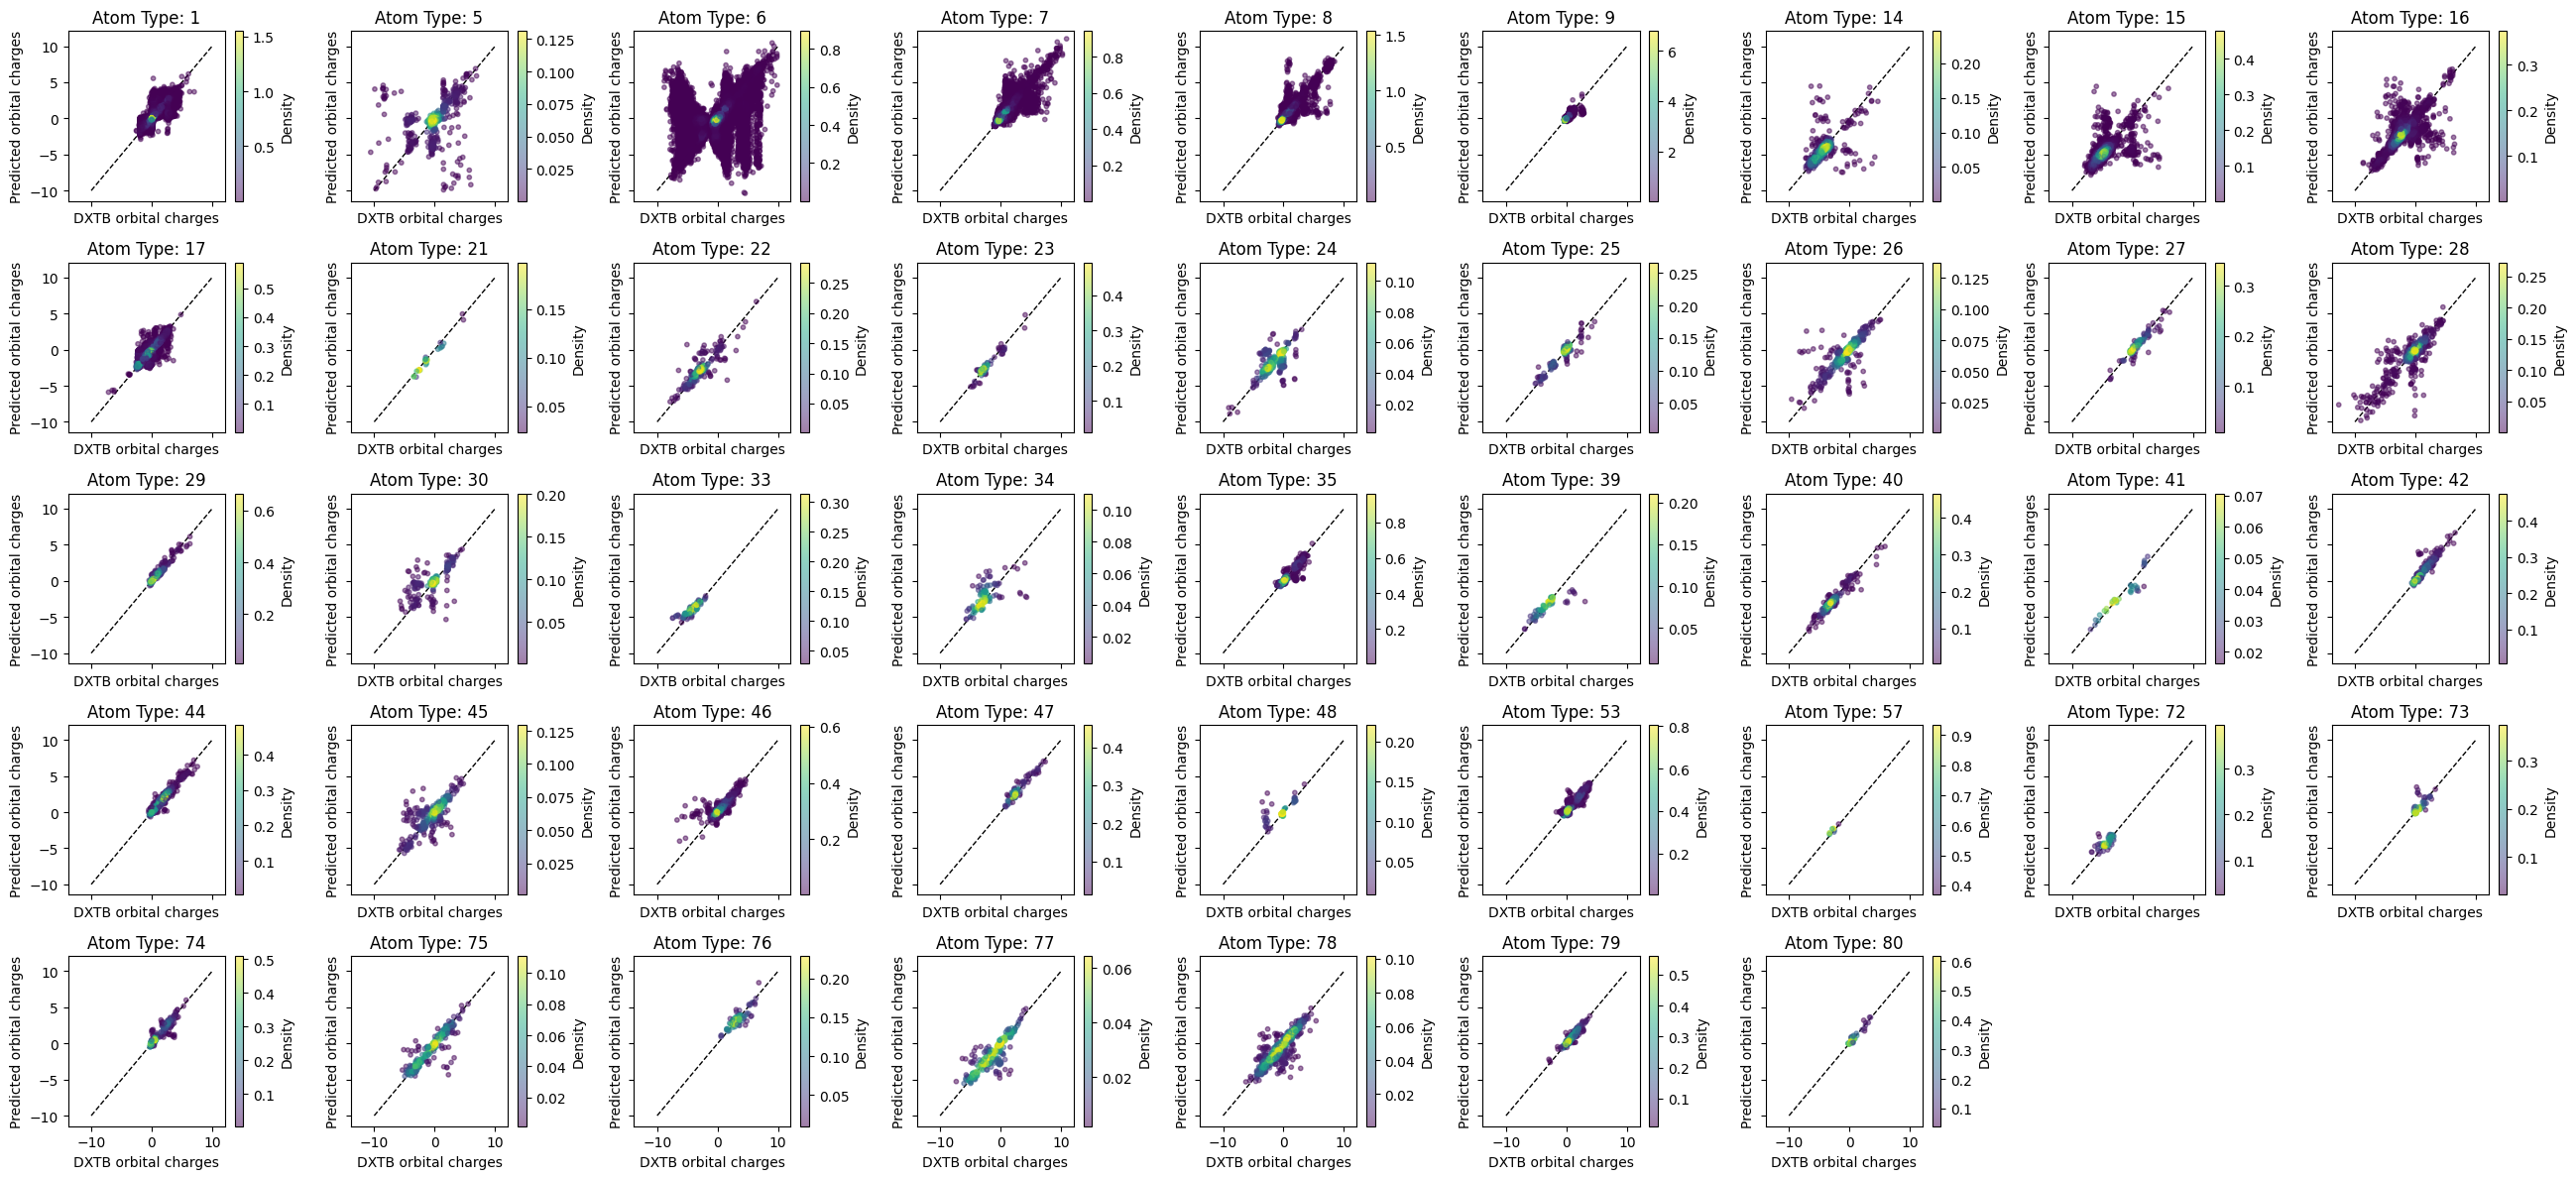

In [ ]:

unique_atom_types = np.unique(atom_types_orbital)
num_atom_types = len(unique_atom_types)

# Create subplots
fig, axes = plt.subplots(ncols=9, nrows=5, figsize=(26, 12), sharey=True, sharex=True)
axes = axes.flatten()

for i, atom_type in enumerate(unique_atom_types):
    print("Subplot for atom type:", atom_type)
    mask = np.array(atom_types_orbital) == atom_type
    x_filtered = outputs['ground_truth'][mask]
    y_filtered = outputs['predictions'][mask]
    xy_filtered = np.vstack([x_filtered, y_filtered])
    z_filtered = gaussian_kde(xy_filtered)(xy_filtered)

    ax = axes[i] if num_atom_types > 1 else axes
    scatter = ax.scatter(x_filtered, y_filtered, s=10, c=z_filtered, cmap='viridis', alpha=0.5)
    ax.plot([-10, 10], [-10, 10], 'k--', linewidth=1, zorder=0)
    ax.set_title(f'Atom Type: {atom_type}')
    ax.set_xlabel('DXTB orbital charges')
    ax.set_ylabel('Predicted orbital charges')
    fig.colorbar(scatter, ax=ax, label='Density')

# Remove empty subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

In [ ]:
outputs = np.load('/home/ihor/projects/MLGuessQC/mlguess/results/TMQM_dxtb_charges_eSCN_K4L2_mse_loss/orbital_charges_epoch_43.npz')

In [ ]:
len(outputs['ground_truth']), len(outputs['predictions'])

(218425, 218425)

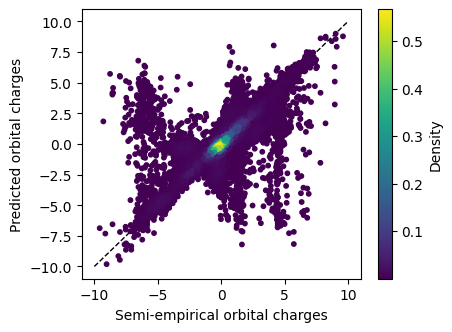

In [ ]:
from scipy.stats import gaussian_kde

# Extract data from the results
x = outputs['ground_truth'][:30000]
y = outputs['predictions'][:30000]

mse = np.mean((x - y) ** 2)
mae = np.mean(np.abs(x - y))

xy = np.vstack([x, y])
z = gaussian_kde(xy)(xy)

# Create the scatter plot
plt.figure(figsize=(4.5, 3.5))
plt.scatter(x, y, c=z, s=10, cmap='viridis', label=f"MSE: {mse:.5f}, MAE: {mae:.4f}")
plt.plot([-10, 10], [-10, 10], 'k--', linewidth=1, zorder=0)
plt.colorbar(label='Density')
plt.xlabel('Semi-empirical orbital charges')
plt.ylabel('Predicted orbital charges')
#plt.legend()
#plt.show()
plt.savefig('orbital_charges_scatter_density_lossMAE.png', dpi=300, bbox_inches='tight')

In [ ]:
orbital_map = np.load('/home/ihor/projects/MLGuessQC/dxtb_orbital_map.npz')

In [ ]:
atom_types_orbital = []
for atom_type in tqdm(outputs["atom_types"]):
    atom_types_orbital.extend([atom_type]*int(orbital_map[str(atom_type)]))


  3%|▎         | 1813/66718 [00:00<00:03, 18127.04it/s]

100%|██████████| 66718/66718 [00:03<00:00, 20527.89it/s]


Subplot for atom type: 1
Subplot for atom type: 5
Subplot for atom type: 6
Subplot for atom type: 7
Subplot for atom type: 8
Subplot for atom type: 9
Subplot for atom type: 14
Subplot for atom type: 15
Subplot for atom type: 16
Subplot for atom type: 17
Subplot for atom type: 21
Subplot for atom type: 22
Subplot for atom type: 23
Subplot for atom type: 24
Subplot for atom type: 25
Subplot for atom type: 26
Subplot for atom type: 27
Subplot for atom type: 28
Subplot for atom type: 29
Subplot for atom type: 30
Subplot for atom type: 33
Subplot for atom type: 34
Subplot for atom type: 35
Subplot for atom type: 39
Subplot for atom type: 40
Subplot for atom type: 41
Subplot for atom type: 42
Subplot for atom type: 44
Subplot for atom type: 45
Subplot for atom type: 46
Subplot for atom type: 47
Subplot for atom type: 48
Subplot for atom type: 53
Subplot for atom type: 57
Subplot for atom type: 72
Subplot for atom type: 73
Subplot for atom type: 74
Subplot for atom type: 75
Subplot for atom t

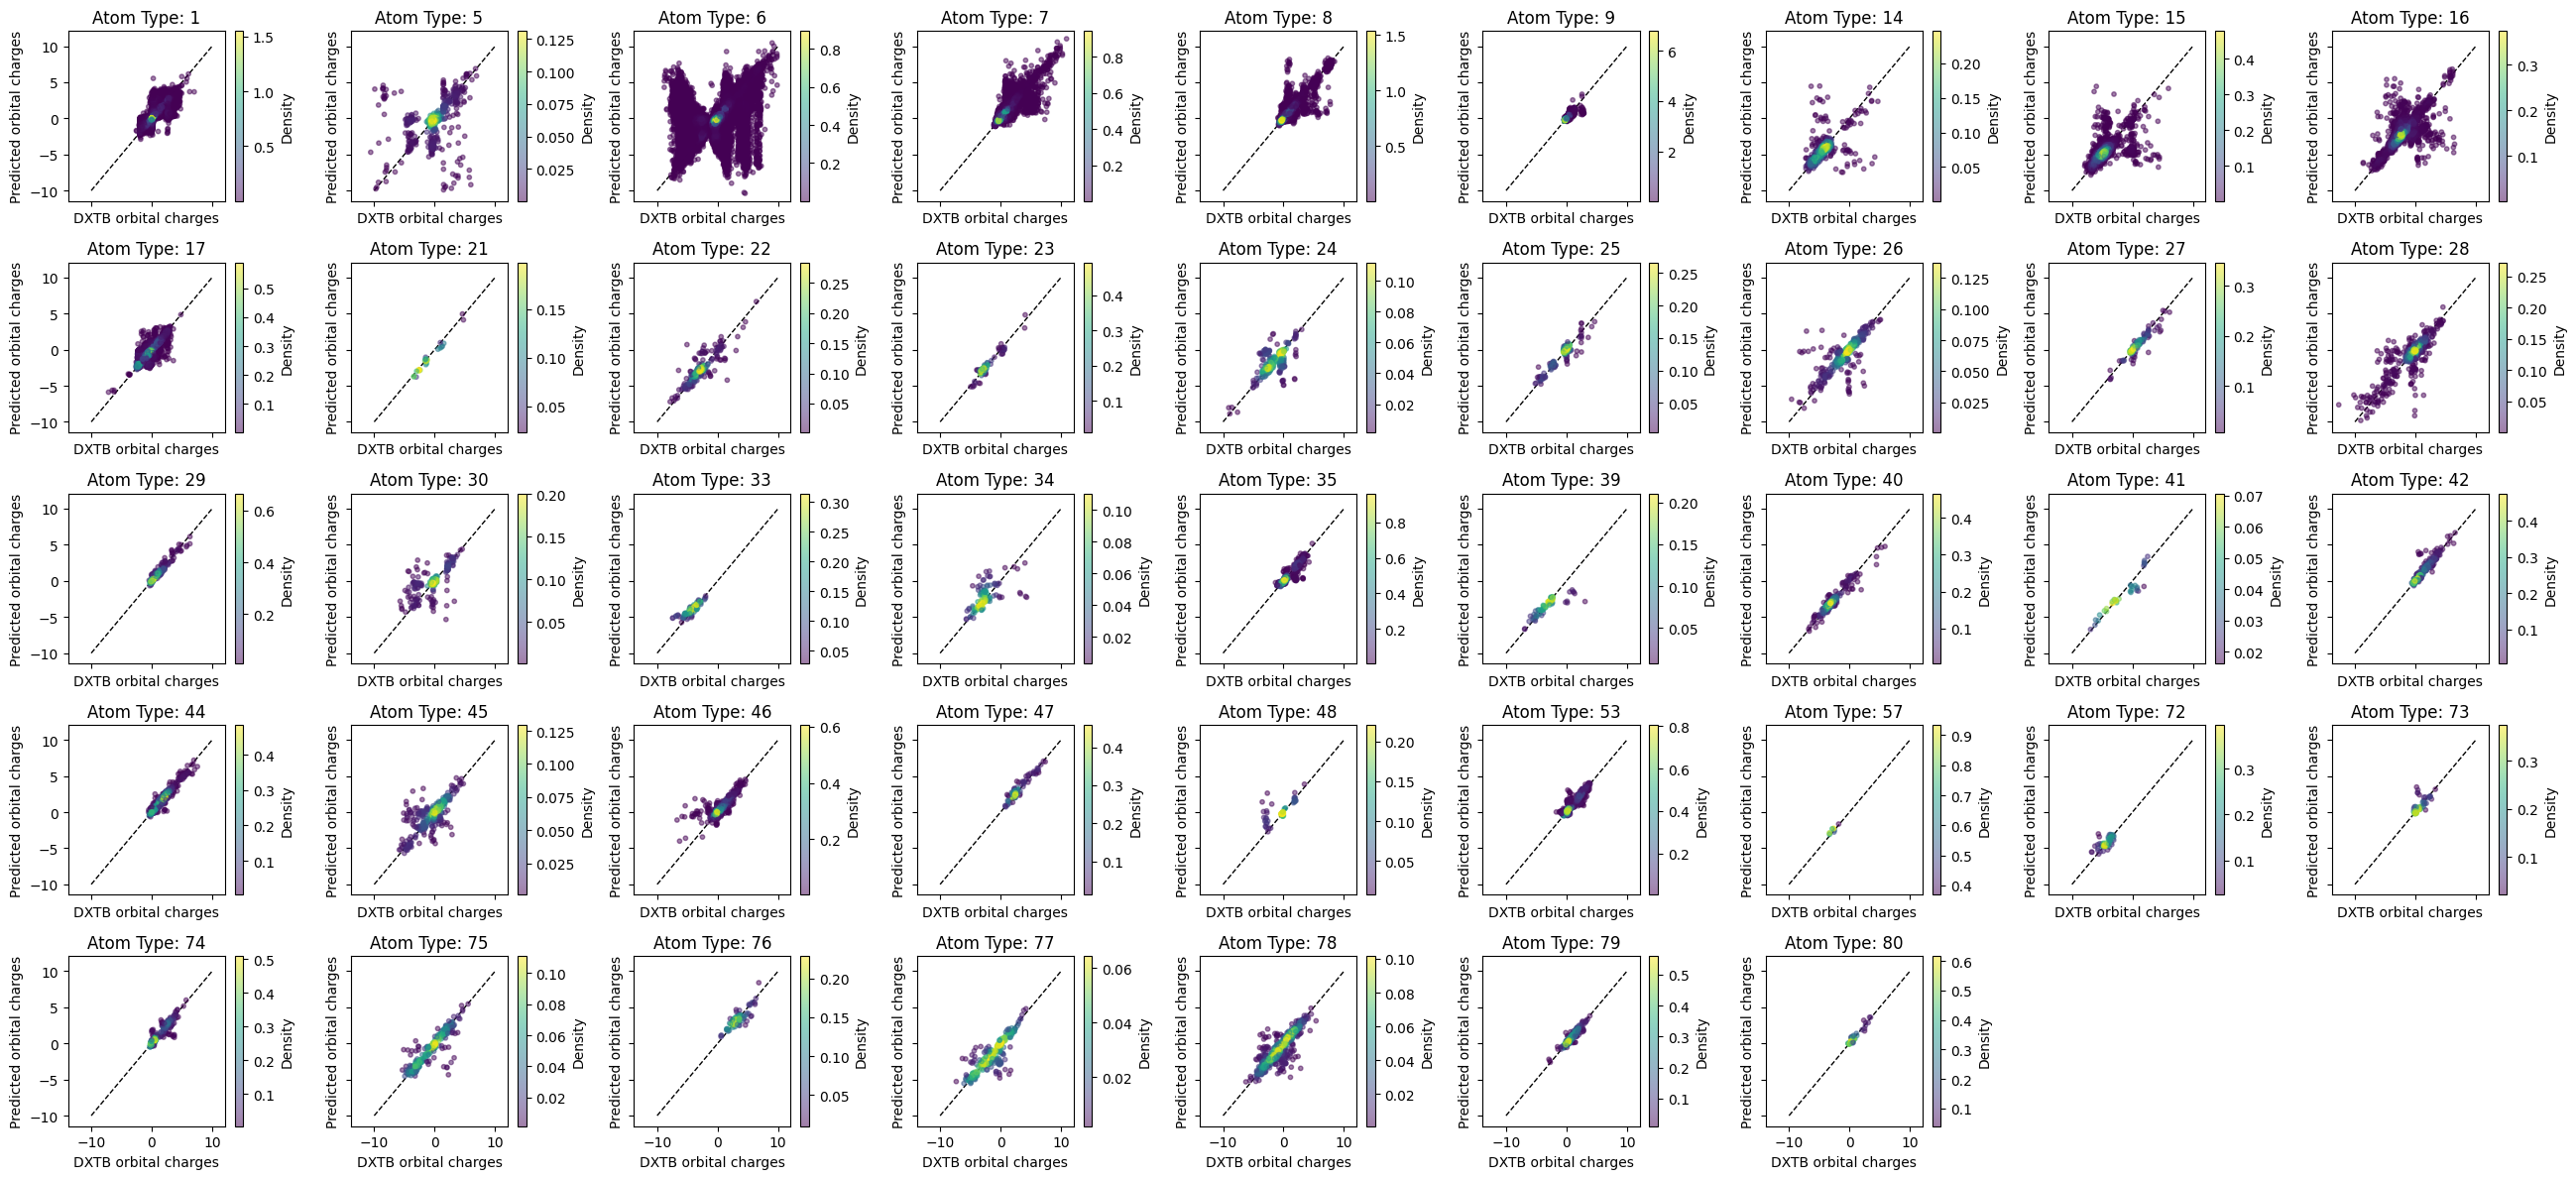

In [ ]:

unique_atom_types = np.unique(atom_types_orbital)
num_atom_types = len(unique_atom_types)

# Create subplots
fig, axes = plt.subplots(ncols=9, nrows=5, figsize=(26, 12), sharey=True, sharex=True)
axes = axes.flatten()

for i, atom_type in enumerate(unique_atom_types):
    print("Subplot for atom type:", atom_type)
    mask = np.array(atom_types_orbital) == atom_type
    x_filtered = outputs['ground_truth'][mask]
    y_filtered = outputs['predictions'][mask]
    xy_filtered = np.vstack([x_filtered, y_filtered])
    z_filtered = gaussian_kde(xy_filtered)(xy_filtered)

    ax = axes[i] if num_atom_types > 1 else axes
    scatter = ax.scatter(x_filtered, y_filtered, s=10, c=z_filtered, cmap='viridis', alpha=0.5)
    ax.plot([-10, 10], [-10, 10], 'k--', linewidth=1, zorder=0)
    ax.set_title(f'Atom Type: {atom_type}')
    ax.set_xlabel('DXTB orbital charges')
    ax.set_ylabel('Predicted orbital charges')
    fig.colorbar(scatter, ax=ax, label='Density')

# Remove empty subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

# Number of SCF with bad fit (epoch 43)

In [4]:
results = np.load('/home/ihor/projects/MLGuessQC/dxtb_experiments/results_ml_guess_eSCN/scf_iterations_mlguess_broyden0p3_eSCN_TMQM_epoch_43.npz')
results

NpzFile '/home/ihor/projects/MLGuessQC/dxtb_experiments/results_ml_guess_eSCN/scf_iterations_mlguess_broyden0p3_eSCN_TMQM_epoch_43.npz' with keys: n_scf_iter_default, n_scf_iter_ml_guess, calc_time_default, calc_time_ml_guess, total_charge_ml_guess...

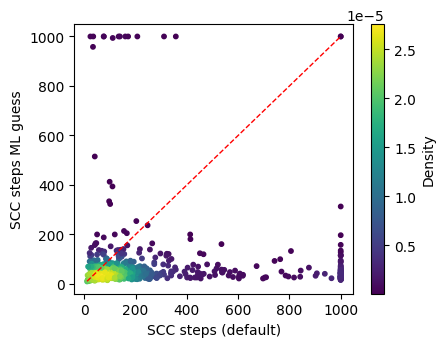

In [5]:
n_scf_iter_default = results['n_scf_iter_default']
n_scf_iter_ml_guess = results['n_scf_iter_ml_guess']

n_scf_default_mean = np.mean(n_scf_iter_default)
n_scf_ml_guess_mean = np.mean(n_scf_iter_ml_guess)
n_scf_default_median = np.median(n_scf_iter_default)
n_scf_ml_guess_median = np.median(n_scf_iter_ml_guess)


xy = np.vstack([n_scf_iter_default.flatten(), n_scf_iter_ml_guess.flatten()])
z = gaussian_kde(xy)(xy)

average_acc = n_scf_default_mean/n_scf_ml_guess_mean

# Create the scatter plot
plt.figure(figsize=(4.5, 3.5))
plt.plot([min(n_scf_iter_default), max(n_scf_iter_default)], 
         [min(n_scf_iter_default), max(n_scf_iter_default)], 
         'r--', linewidth=1, zorder=2)
plt.scatter(n_scf_iter_default, n_scf_iter_ml_guess, c=z, s=10, cmap='viridis', 
            label="Avergae Acceleration: {:.1f}".format(average_acc))
#plt.legend(loc='upper right')
plt.colorbar(label='Density')
plt.xlabel('SCC steps (default)')
plt.ylabel('SCC steps ML guess')
#plt.title('tmQM Acceleration')
#plt.show()
plt.savefig('tmQM_acceleration.png', dpi=300, bbox_inches='tight')

In [6]:
for key in results.keys():
    print(key)

n_scf_iter_default
n_scf_iter_ml_guess
calc_time_default
calc_time_ml_guess
total_charge_ml_guess
charge_mse
charge_mae
potential_mse
potential_mae


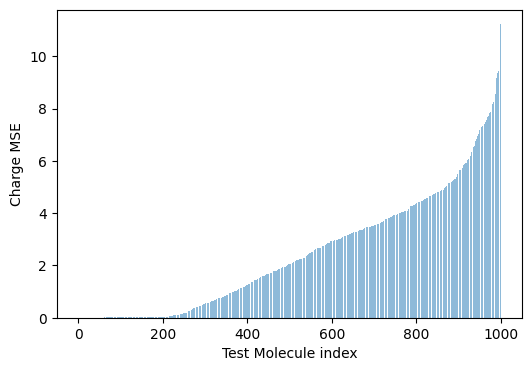

In [7]:
fig = plt.figure(figsize=(6, 4))
plt.bar(np.arange(len(results['charge_mse'])), np.sort(results['charge_mse']), alpha=0.5, label='Charge MSE')
plt.xlabel('Test Molecule index')
plt.ylabel('Charge MSE')
#plt.grid("-", alpha=0.5)
plt.show()


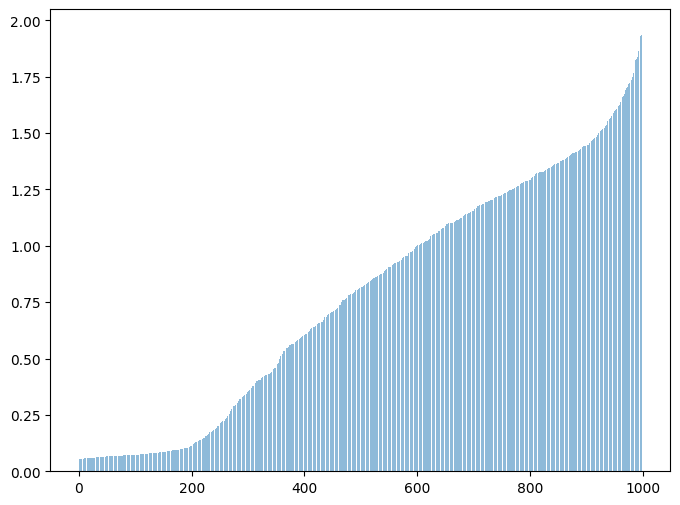

In [8]:
fig = plt.figure(figsize=(8, 6))
plt.bar(np.arange(len(results['charge_mae'])), np.sort(results['charge_mae']), alpha=0.5, label='Charge MSE')
plt.show()


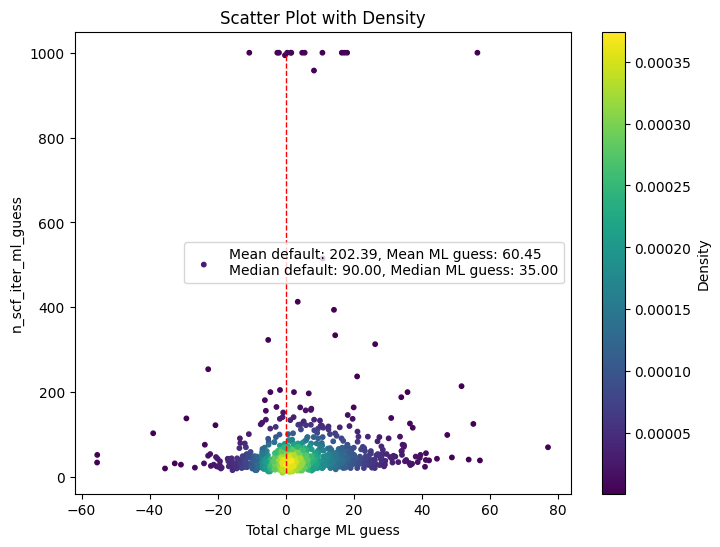

In [9]:
n_scf_iter_default = results['n_scf_iter_default'].flatten() 
n_scf_iter_ml_guess = results['n_scf_iter_ml_guess'].flatten() 
total_charge_ml_guess = results['total_charge_ml_guess'].flatten()

n_scf_default_mean = np.mean(n_scf_iter_default)
n_scf_ml_guess_mean = np.mean(n_scf_iter_ml_guess)
n_scf_default_median = np.median(n_scf_iter_default)
n_scf_ml_guess_median = np.median(n_scf_iter_ml_guess)


xy = np.vstack([total_charge_ml_guess, n_scf_iter_ml_guess.flatten()])
z = gaussian_kde(xy)(xy)


# Create the scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(total_charge_ml_guess, n_scf_iter_ml_guess, c=z, s=10, cmap='viridis', 
            label="Mean default: {:.2f}, Mean ML guess: {:.2f} \nMedian default: {:.2f}, Median ML guess: {:.2f}".format(n_scf_default_mean, n_scf_ml_guess_mean, n_scf_default_median, n_scf_ml_guess_median))
plt.vlines(x=0, ymin=min(n_scf_iter_ml_guess), ymax=max(n_scf_iter_ml_guess), color='r', linestyle='--', linewidth=1, zorder=2)
plt.legend()
plt.colorbar(label='Density')
plt.xlabel('Total charge ML guess')
plt.ylabel('n_scf_iter_ml_guess')
plt.title('Scatter Plot with Density')
plt.show()

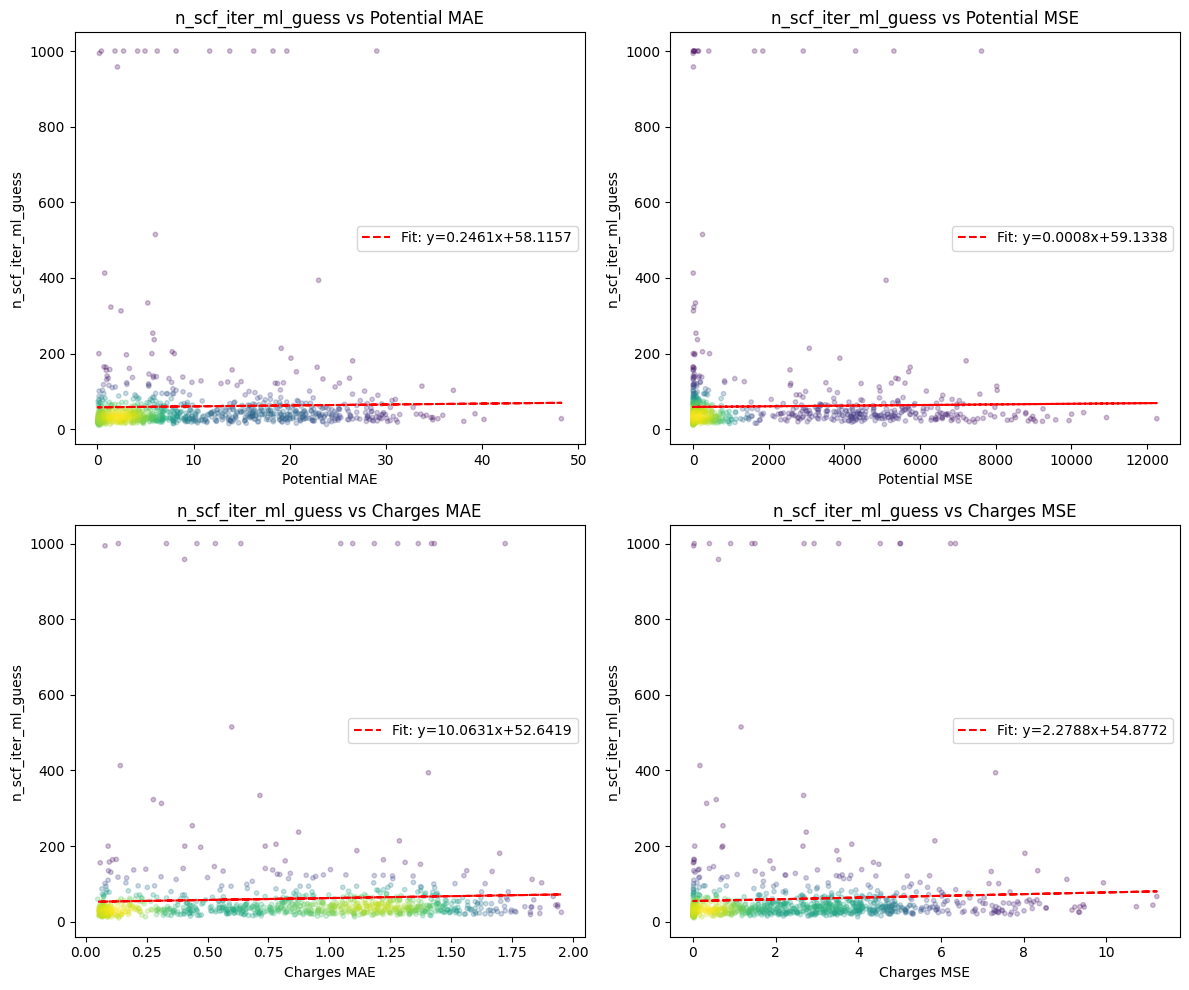

In [10]:
from scipy.stats import linregress

n_scf_iter_default = results['n_scf_iter_default'].flatten()
n_scf_iter_ml_guess = results['n_scf_iter_ml_guess'].flatten()

n_scf_default_mean = np.mean(n_scf_iter_default)
n_scf_ml_guess_mean = np.mean(n_scf_iter_ml_guess)
n_scf_default_median = np.median(n_scf_iter_default)
n_scf_ml_guess_median = np.median(n_scf_iter_ml_guess)



# Create subplots with 4 axes
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 10))

# Plot n_scf_iter_ml_guess vs potential_mae
xy = np.vstack([results['potential_mae'].flatten(), n_scf_iter_ml_guess])
z = gaussian_kde(xy)(xy)
slope, intercept, r_value, p_value, std_err = linregress(results['potential_mae'].flatten(), n_scf_iter_ml_guess)
axes[0, 0].scatter(results['potential_mae'], n_scf_iter_ml_guess, c=z, s=10, cmap='viridis', alpha=0.25)
axes[0, 0].plot(results['potential_mae'], slope * results['potential_mae'] + intercept, 'r--', label=f'Fit: y={slope:.4f}x+{intercept:.4f}')
axes[0, 0].set_title('n_scf_iter_ml_guess vs Potential MAE')
axes[0, 0].set_xlabel('Potential MAE')
axes[0, 0].set_ylabel('n_scf_iter_ml_guess')
#axes[0, 0].set_xlim(0, 20)
axes[0, 0].legend()

# Plot n_scf_iter_ml_guess vs potential_mse
xy = np.vstack([results['potential_mse'].flatten(), n_scf_iter_ml_guess])
z = gaussian_kde(xy)(xy)
slope, intercept, r_value, p_value, std_err = linregress(results['potential_mse'].flatten(), n_scf_iter_ml_guess)
axes[0, 1].scatter(results['potential_mse'], n_scf_iter_ml_guess, c=z, s=10, cmap='viridis', alpha=0.25)
axes[0, 1].plot(results['potential_mse'], slope * results['potential_mse'] + intercept, 'r--', label=f'Fit: y={slope:.4f}x+{intercept:.4f}')
axes[0, 1].set_title('n_scf_iter_ml_guess vs Potential MSE')
axes[0, 1].set_xlabel('Potential MSE')
axes[0, 1].set_ylabel('n_scf_iter_ml_guess')
#axes[0, 1].set_xlim(0, 20)
axes[0, 1].legend()

# Plot n_scf_iter_ml_guess vs charges_mae
xy = np.vstack([results['charge_mae'].flatten(), n_scf_iter_ml_guess])
z = gaussian_kde(xy)(xy)
slope, intercept, r_value, p_value, std_err = linregress(results['charge_mae'].flatten(), n_scf_iter_ml_guess)
axes[1, 0].scatter(results['charge_mae'], n_scf_iter_ml_guess, c=z, s=10, cmap='viridis', alpha=0.25)
axes[1, 0].plot(results['charge_mae'], slope * results['charge_mae'] + intercept, 'r--', label=f'Fit: y={slope:.4f}x+{intercept:.4f}')
axes[1, 0].set_title('n_scf_iter_ml_guess vs Charges MAE')
axes[1, 0].set_xlabel('Charges MAE')
axes[1, 0].set_ylabel('n_scf_iter_ml_guess')
#axes[1, 0].set_xlim(0, 20)
axes[1, 0].legend()

# Plot n_scf_iter_ml_guess vs charges_mse
xy = np.vstack([results['charge_mse'].flatten(), n_scf_iter_ml_guess])
z = gaussian_kde(xy)(xy)
slope, intercept, r_value, p_value, std_err = linregress(results['charge_mse'].flatten(), n_scf_iter_ml_guess)
axes[1, 1].scatter(results['charge_mse'], n_scf_iter_ml_guess, c=z, s=10, cmap='viridis', alpha=0.25)
axes[1, 1].plot(results['charge_mse'], slope * results['charge_mse'] + intercept, 'r--', label=f'Fit: y={slope:.4f}x+{intercept:.4f}')
axes[1, 1].set_title('n_scf_iter_ml_guess vs Charges MSE')
axes[1, 1].set_xlabel('Charges MSE')
axes[1, 1].set_ylabel('n_scf_iter_ml_guess')
#axes[1, 1].set_xlim(0, 20)
axes[1, 1].legend()

# Adjust layout and show the plot
plt.tight_layout()
plt.show()

# Train on all tmQM (K4L2M2)

In [59]:
outputs = np.load('/home/ihor/projects/MLGuessQC/mlguess/results/tmQMneutral_clean_cdr/orbital_charges_epoch_67.npz')

In [12]:
for key in outputs.keys():
    print(key)

n_atom
atom_types
coords
ground_truth
predictions


In [13]:
len(outputs['ground_truth']), len(outputs['predictions'])

(56571, 56571)

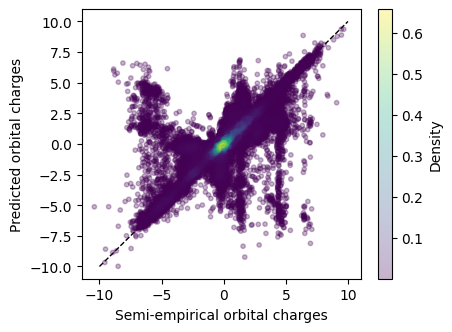

In [14]:
from scipy.stats import gaussian_kde

# Extract data from the results
x = outputs['ground_truth']#[:3000]
y = outputs['predictions']#[:3000]

mse = np.mean((x - y) ** 2)
mae = np.mean(np.abs(x - y))

xy = np.vstack([x, y])
z = gaussian_kde(xy)(xy)

# Create the scatter plot
plt.figure(figsize=(4.5, 3.5))
plt.scatter(x, y, c=z, s=10, alpha=0.3, cmap='viridis', label=f"MSE: {mse:.5f}, MAE: {mae:.4f}")
plt.plot([-10, 10], [-10, 10], 'k--', linewidth=1, zorder=0)
plt.colorbar(label='Density')
plt.xlabel('Semi-empirical orbital charges')
plt.ylabel('Predicted orbital charges')
#plt.legend()
plt.show()
#plt.savefig('orbital_charges_scatter_density_lossMAE.png', dpi=300, bbox_inches='tight')

In [15]:
orbital_map = np.load('/home/ihor/projects/MLGuessQC/dxtb_experiments/dxtb_orbital_map.npz')

In [16]:
atom_types_orbital = []
for atom_type in tqdm(outputs["atom_types"]):
    atom_types_orbital.extend([atom_type]*int(orbital_map[str(atom_type)]))


 11%|█▏        | 1941/17123 [00:00<00:00, 19401.18it/s]

100%|██████████| 17123/17123 [00:00<00:00, 19039.92it/s]


Subplot for atom type: 1
Subplot for atom type: 5
Subplot for atom type: 6
Subplot for atom type: 7
Subplot for atom type: 8
Subplot for atom type: 9
Subplot for atom type: 14
Subplot for atom type: 15
Subplot for atom type: 16
Subplot for atom type: 17
Subplot for atom type: 21
Subplot for atom type: 22
Subplot for atom type: 24
Subplot for atom type: 25
Subplot for atom type: 26
Subplot for atom type: 27
Subplot for atom type: 28
Subplot for atom type: 29
Subplot for atom type: 30
Subplot for atom type: 33
Subplot for atom type: 34
Subplot for atom type: 35
Subplot for atom type: 39
Subplot for atom type: 40
Subplot for atom type: 41
Subplot for atom type: 42
Subplot for atom type: 43
Subplot for atom type: 44
Subplot for atom type: 45
Subplot for atom type: 46
Subplot for atom type: 47
Subplot for atom type: 48
Subplot for atom type: 53
Subplot for atom type: 72
Subplot for atom type: 73
Subplot for atom type: 74
Subplot for atom type: 75
Subplot for atom type: 76
Subplot for atom t

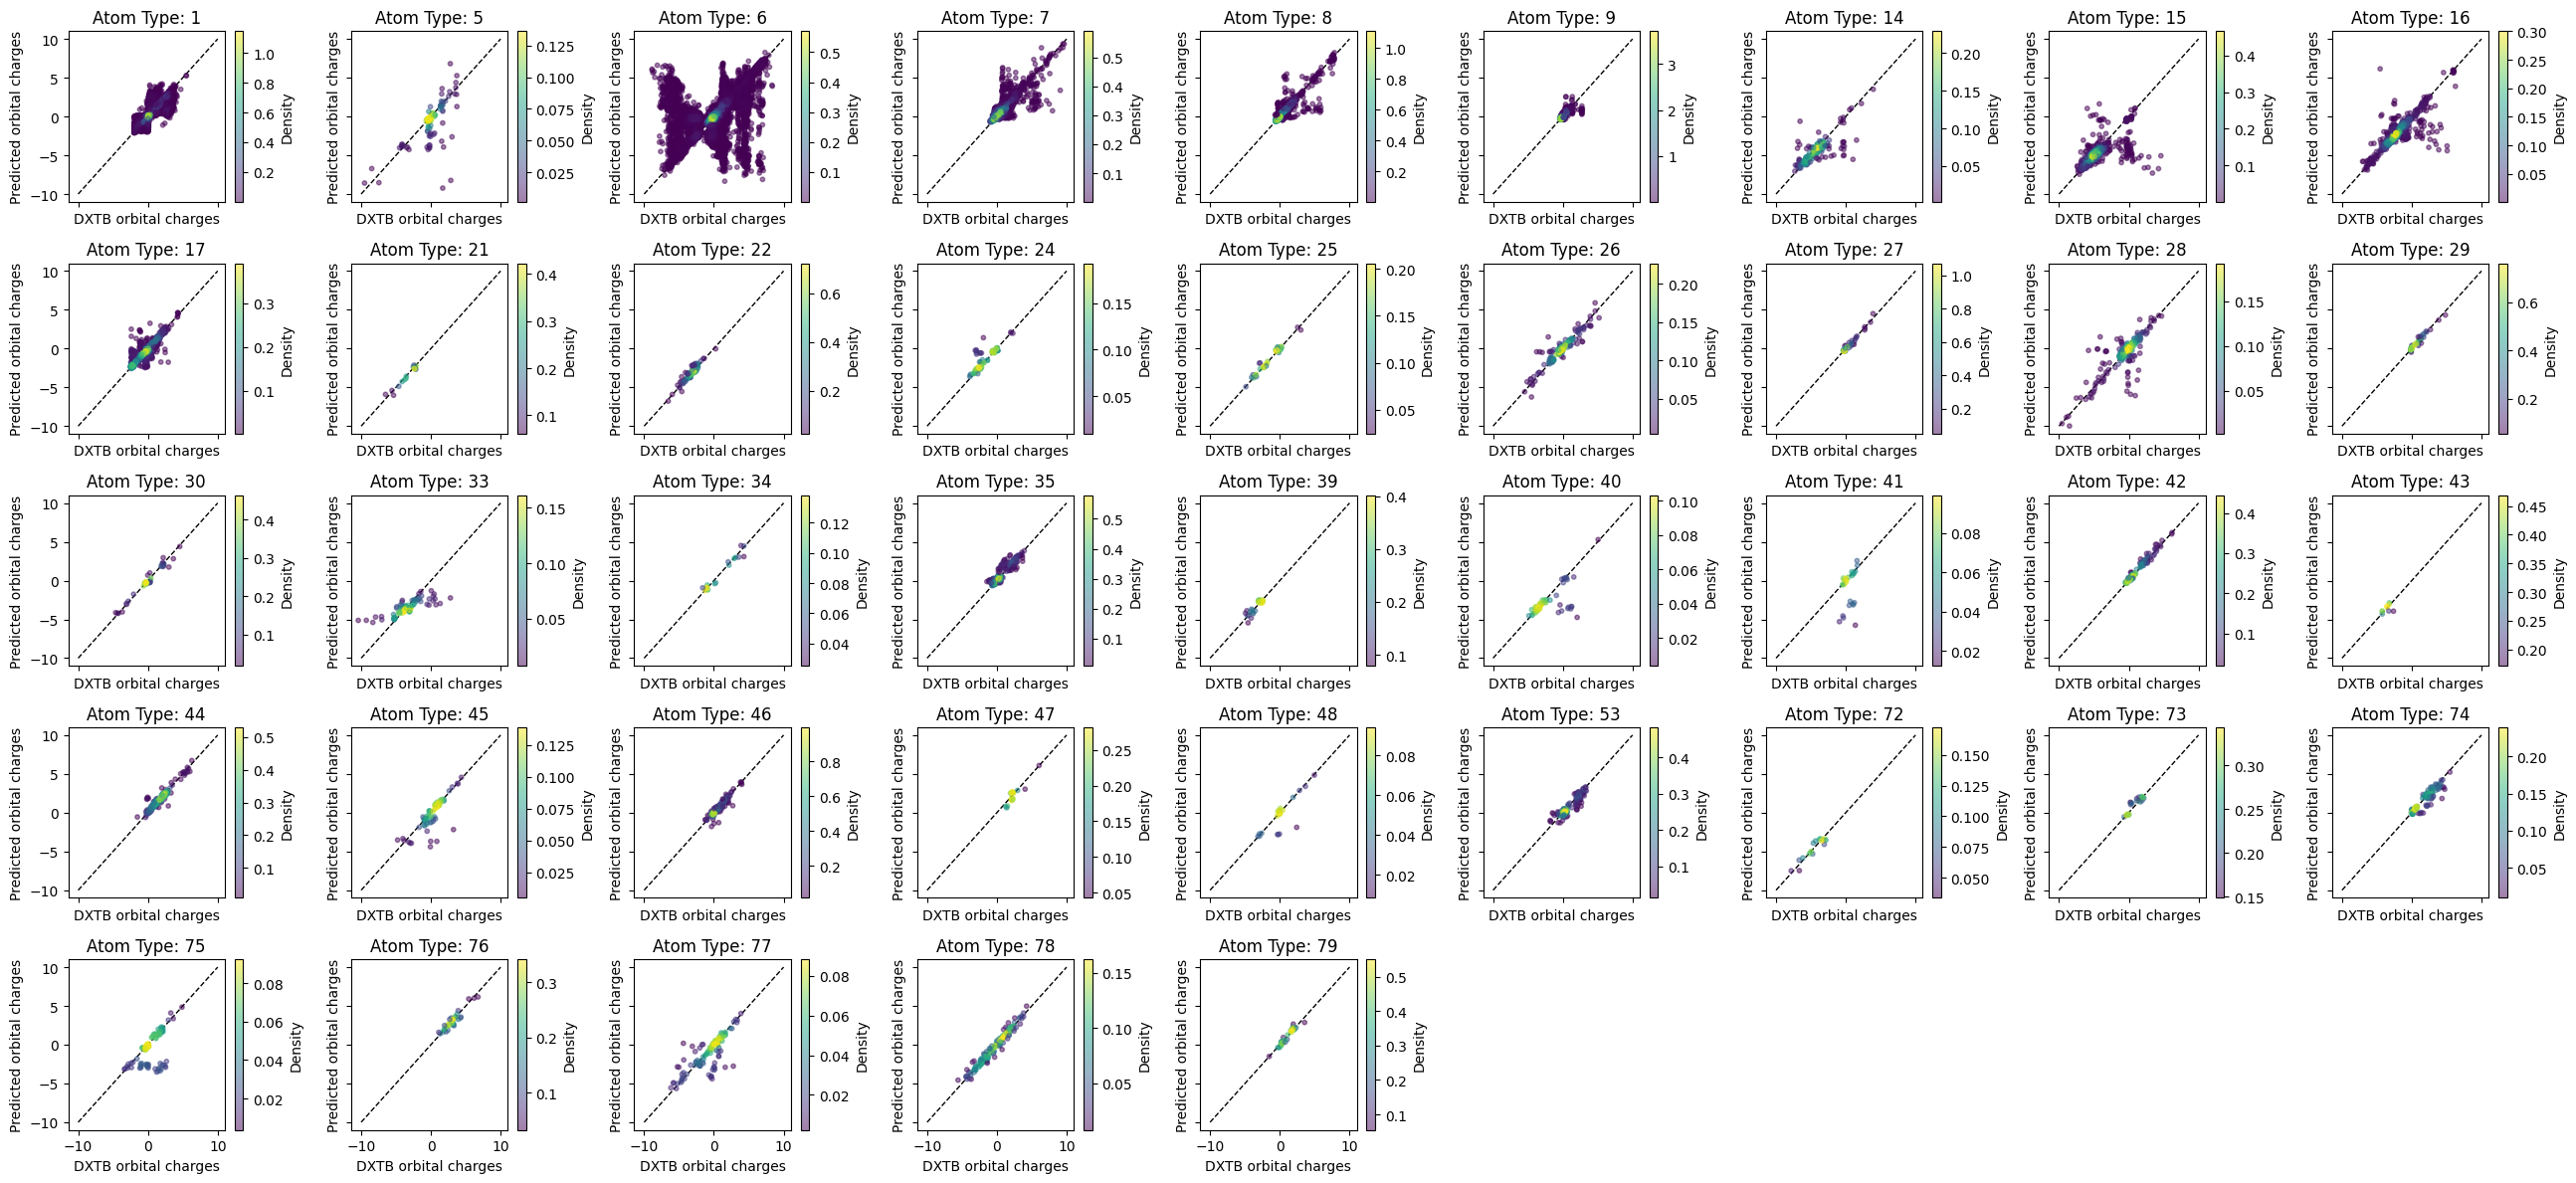

In [17]:

unique_atom_types = np.unique(atom_types_orbital)
num_atom_types = len(unique_atom_types)

# Create subplots
fig, axes = plt.subplots(ncols=9, nrows=5, figsize=(26, 12), sharey=True, sharex=True)
axes = axes.flatten()

for i, atom_type in enumerate(unique_atom_types):
    print("Subplot for atom type:", atom_type)
    mask = np.array(atom_types_orbital) == atom_type
    x_filtered = outputs['ground_truth'][mask]
    y_filtered = outputs['predictions'][mask]
    xy_filtered = np.vstack([x_filtered, y_filtered])
    z_filtered = gaussian_kde(xy_filtered)(xy_filtered)

    ax = axes[i] if num_atom_types > 1 else axes
    scatter = ax.scatter(x_filtered, y_filtered, s=10, c=z_filtered, cmap='viridis', alpha=0.5)
    ax.plot([-10, 10], [-10, 10], 'k--', linewidth=1, zorder=0)
    ax.set_title(f'Atom Type: {atom_type}')
    ax.set_xlabel('DXTB orbital charges')
    ax.set_ylabel('Predicted orbital charges')
    fig.colorbar(scatter, ax=ax, label='Density')

# Remove empty subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

In [18]:
atom_types_orbital = np.array(atom_types_orbital)

In [19]:
atom_types_orbital[atom_types_orbital == 6]

array([6, 6, 6, ..., 6, 6, 6])

In [20]:
chunks_predictions = [outputs['predictions'][atom_types_orbital == 6][i:i+4] for i in range(0, outputs['predictions'][atom_types_orbital == 6].shape[0], 4)]

In [21]:
chunks_targets = [outputs['ground_truth'][atom_types_orbital == 6][i:i+4] for i in range(0, outputs['ground_truth'][atom_types_orbital == 6].shape[0], 4)]

In [22]:
C_orbital_charges_pred = {"s": [], "p": []}
C_orbital_charges_target = {"s": [], "p": []}
for chunk_pred, chunk_target in zip(chunks_predictions, chunks_targets):
    C_orbital_charges_pred["s"].append(chunk_pred[0])
    C_orbital_charges_pred["p"].extend(chunk_pred[1:4])
    C_orbital_charges_target["s"].append(chunk_target[0])
    C_orbital_charges_target["p"].extend(chunk_target[1:4])
    
    
    

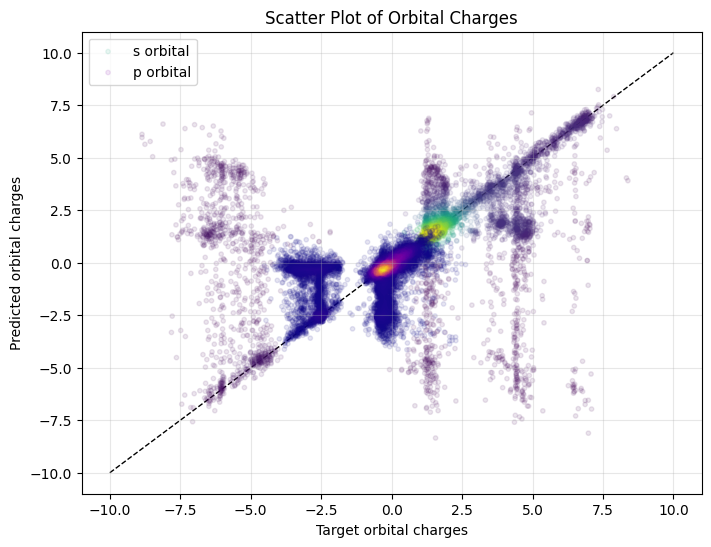

In [23]:
# Scatter plot for s and p orbital charges
plt.figure(figsize=(8, 6))

# Plot s orbital charges
xy = np.vstack([C_orbital_charges_target['s'], C_orbital_charges_pred['s']])
z = gaussian_kde(xy)(xy)
plt.scatter(C_orbital_charges_target['s'], C_orbital_charges_pred['s'], c=z, s=10, cmap='viridis', alpha=0.1, label='s orbital')

# Plot p orbital charges
xy = np.vstack([C_orbital_charges_target['p'], C_orbital_charges_pred['p']])
z = gaussian_kde(xy)(xy)
plt.scatter(C_orbital_charges_target['p'], C_orbital_charges_pred['p'], c=z, s=10, cmap='plasma', alpha=0.1, label='p orbital')

# Add diagonal line
plt.plot([-10, 10], [-10, 10], 'k--', linewidth=1, zorder=0)

# Add labels and legend
plt.xlabel('Target orbital charges')
plt.ylabel('Predicted orbital charges')
plt.title('Scatter Plot of Orbital Charges')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [25]:
def process_npz_file(file_path):
    """
    Process a single NPZ file and extract the relevant data.
    """
    data = np.load(file_path)
    orbital_map = np.load("/home/ihor/projects/MLGuessQC/dxtb_experiments/dxtb_orbital_map.npz")
    
    mol_numbers = []
    mol_positions = []
    mol_charges_targer = []
    mol_charges_pred = []
    n_atom = data["n_atom"]
    flat_numbers = data["atom_types"]
    flat_positions = data["coords"]
    flat_charges_targer = data["ground_truth"]
    flat_charges_pred = data["predictions"]
    start_atom_idx = 0
    start_orbital_idx = 0
    for i in range(len(n_atom)):
        n = n_atom[i]
        mol_numbers.append(flat_numbers[start_atom_idx:start_atom_idx + n])
        n_orbitals = 0
        for atom in flat_numbers[start_atom_idx:start_atom_idx + n]:
            n_orbitals += orbital_map[str(atom)]
 
        mol_charges_pred.append(flat_charges_pred[start_orbital_idx:start_orbital_idx + n_orbitals])
        mol_charges_targer.append(flat_charges_targer[start_orbital_idx:start_orbital_idx + n_orbitals])
        mol_positions.append(flat_positions[start_atom_idx:start_atom_idx + n])
        start_atom_idx += n
        start_orbital_idx += n_orbitals
    
    return mol_numbers, mol_positions, mol_charges_targer, mol_charges_pred

In [61]:
mol_numbers, mol_positions, mol_charges_target, mol_charges_pred = process_npz_file('/home/ihor/projects/MLGuessQC/mlguess/results/tmQMneutral_clean_cdr/orbital_charges_epoch_67.npz')

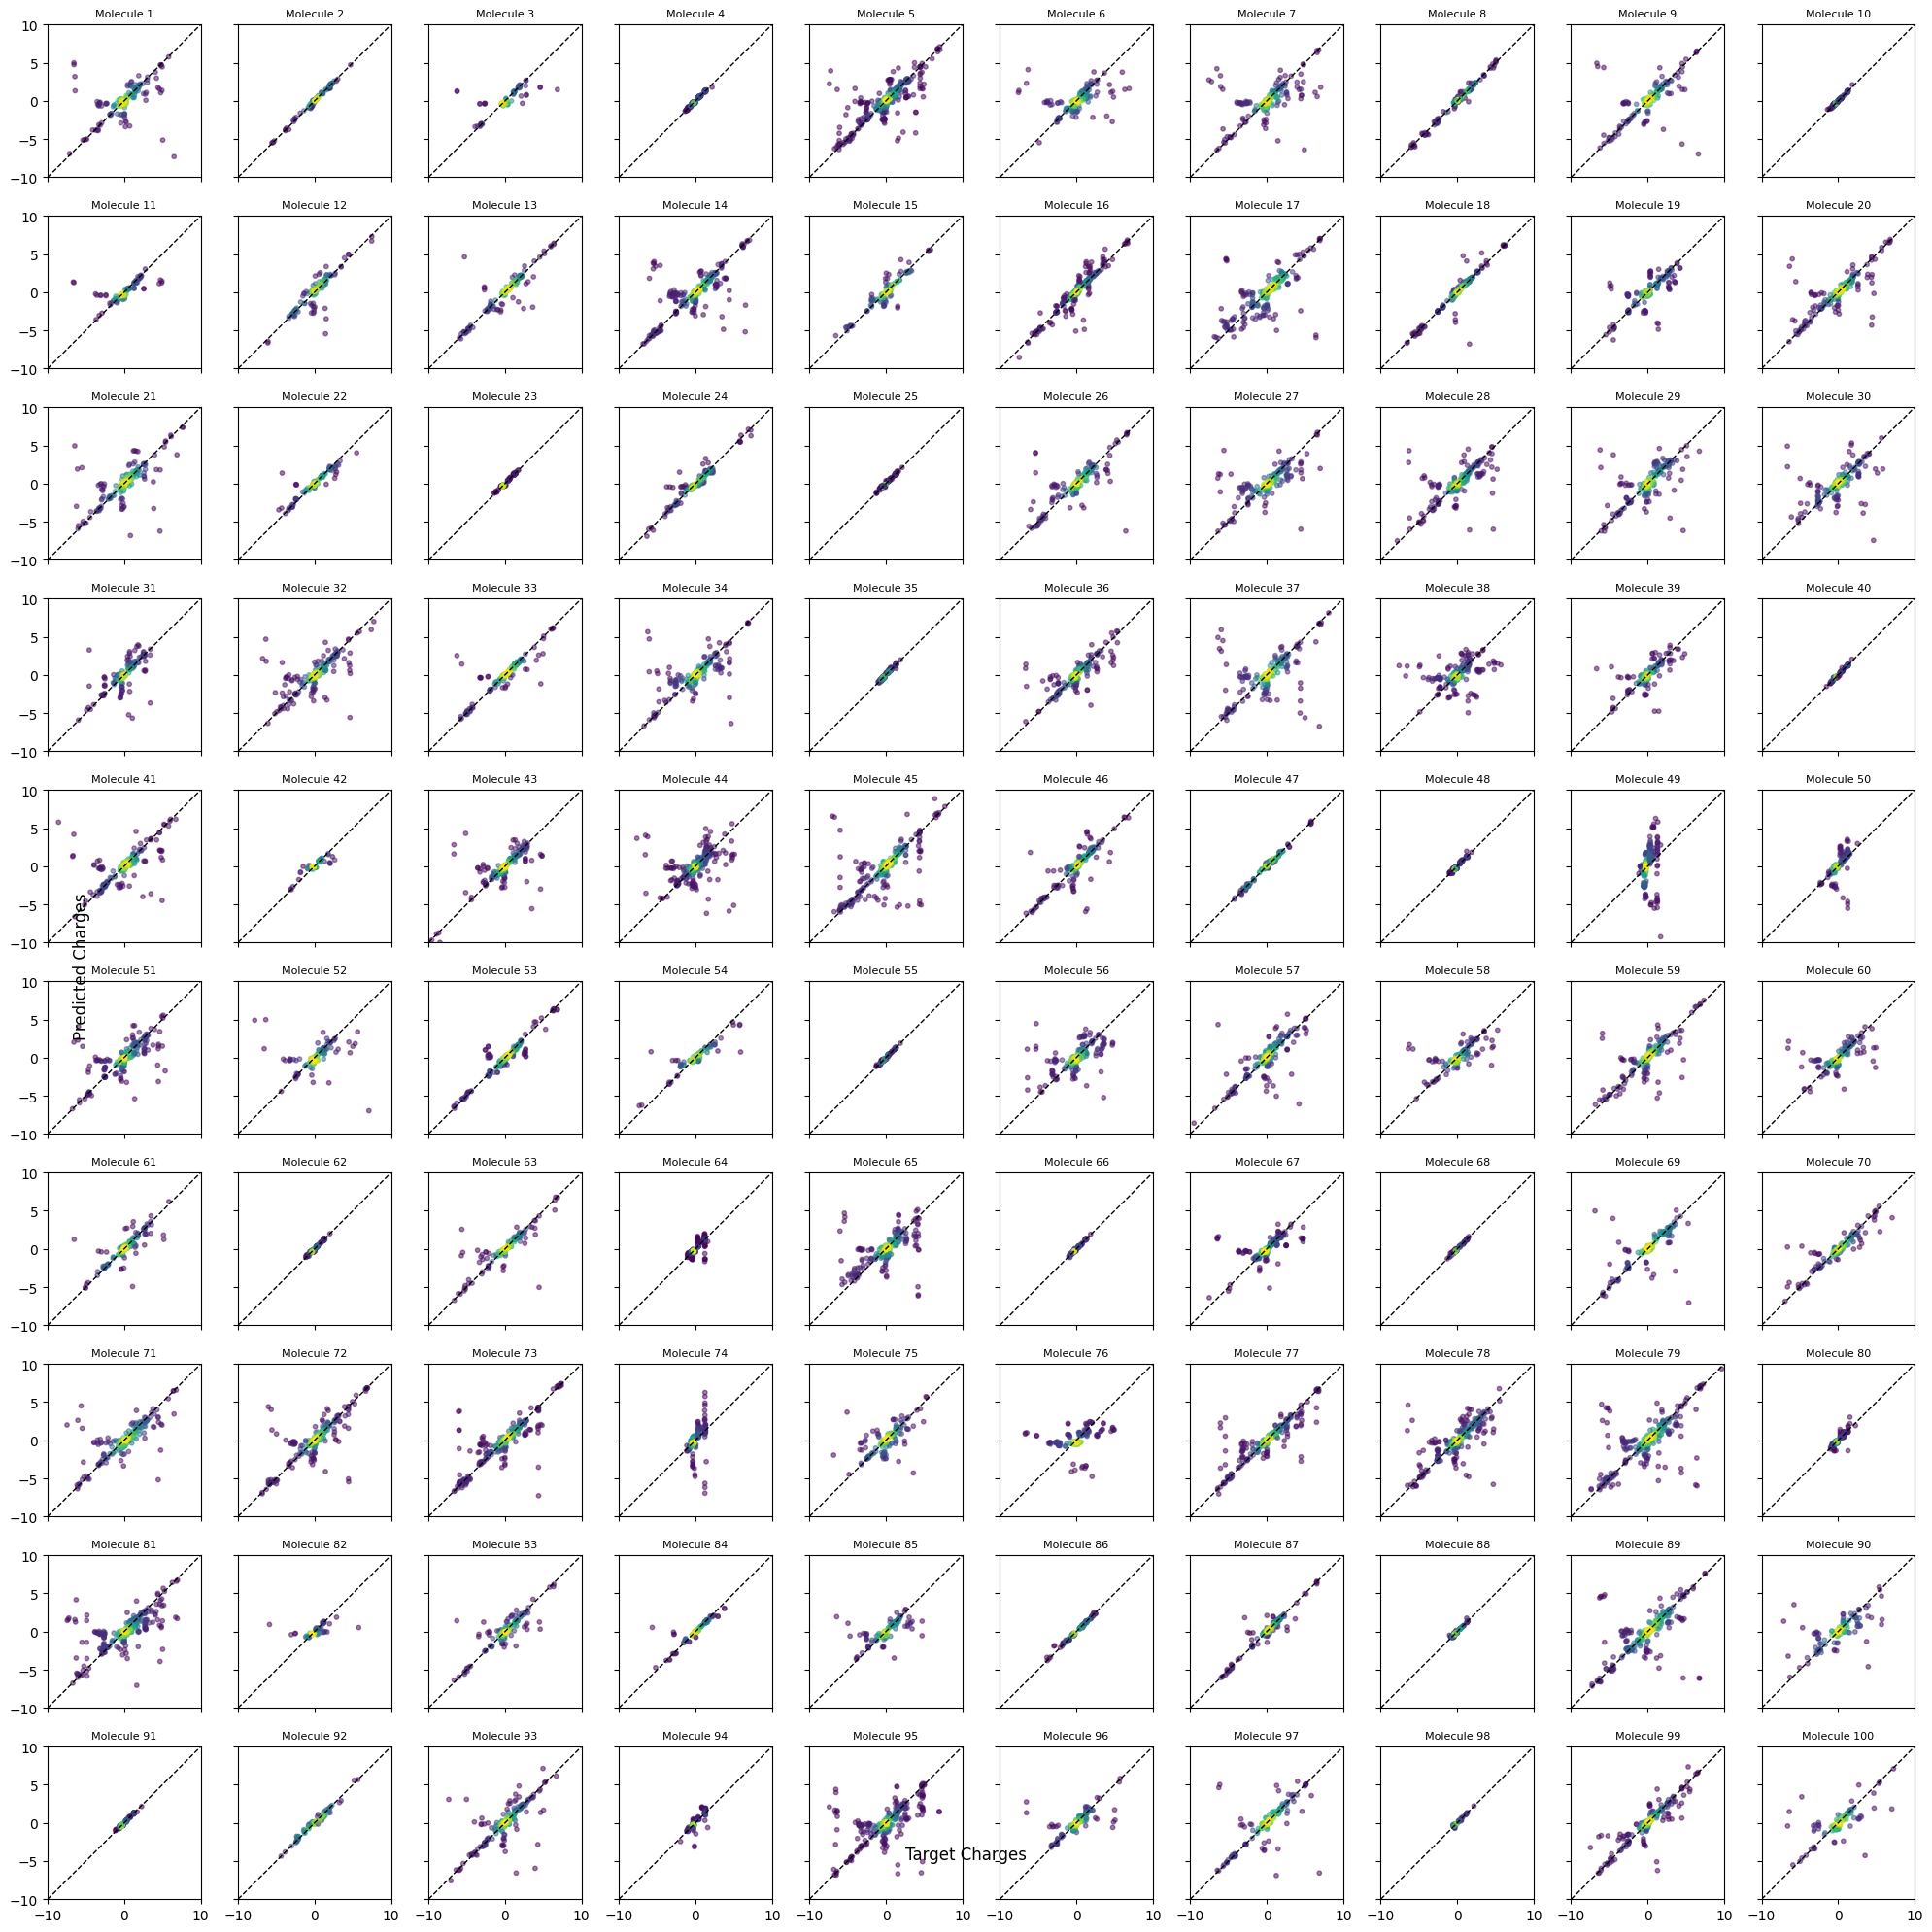

In [27]:
# Create a 10x10 grid of subplots
fig, axes = plt.subplots(nrows=10, ncols=10, figsize=(20, 20), sharex=True, sharey=True)
axes = axes.flatten()

# Plot each molecule's data in a separate subplot
for idx, (charges_target, charges_pred) in enumerate(zip(mol_charges_target, mol_charges_pred)):
    if idx >= 100:  # Limit to 100 subplots
        break
    ax = axes[idx]
    xy_filtered = np.vstack([charges_target, charges_pred])
    z_filtered = gaussian_kde(xy_filtered)(xy_filtered)
    ax.scatter(charges_target, charges_pred, s=10, alpha=0.5, c=z_filtered)
    ax.plot([-10, 10], [-10, 10], 'k--', linewidth=1)  # Diagonal line
    ax.set_title(f'Molecule {idx + 1}', fontsize=8)
    ax.set_xlim(-10, 10)
    ax.set_ylim(-10, 10)

# Remove unused subplots
for j in range(idx + 1, len(axes)):
    fig.delaxes(axes[j])

# Add common labels
fig.text(0.5, 0.04, 'Target Charges', ha='center', fontsize=12)
fig.text(0.04, 0.5, 'Predicted Charges', va='center', rotation='vertical', fontsize=12)

plt.tight_layout()
plt.show()

In [60]:
mol_mse = [np.mean((target - pred) ** 2) for target, pred in zip(mol_charges_target, mol_charges_pred)]
mol_n_atoms = [len(mol) for mol in mol_numbers]

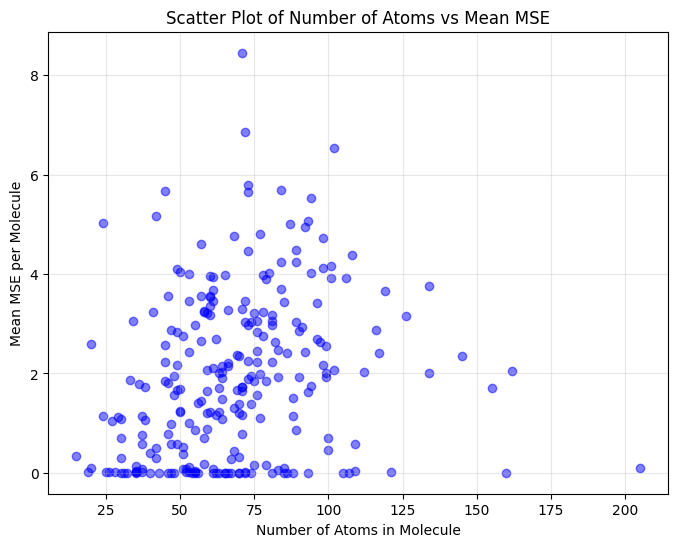

In [29]:


# Create the scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(mol_n_atoms, mol_mse, alpha=0.5, color='blue')
plt.xlabel('Number of Atoms in Molecule')
plt.ylabel('Mean MSE per Molecule')
plt.title('Scatter Plot of Number of Atoms vs Mean MSE')
plt.grid(alpha=0.3)
plt.show()

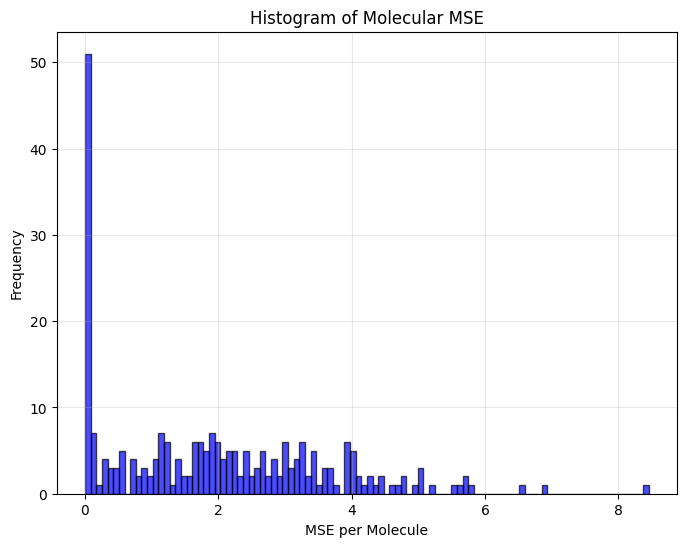

In [30]:
# Plot histogram of mol_mse
plt.figure(figsize=(8, 6))
plt.hist(mol_mse, bins=100, color='blue', alpha=0.7, edgecolor='black')
plt.xlabel('MSE per Molecule')
plt.ylabel('Frequency')
plt.title('Histogram of Molecular MSE')
plt.grid(alpha=0.3)
plt.show()

In [31]:
len(mol_mse)

250

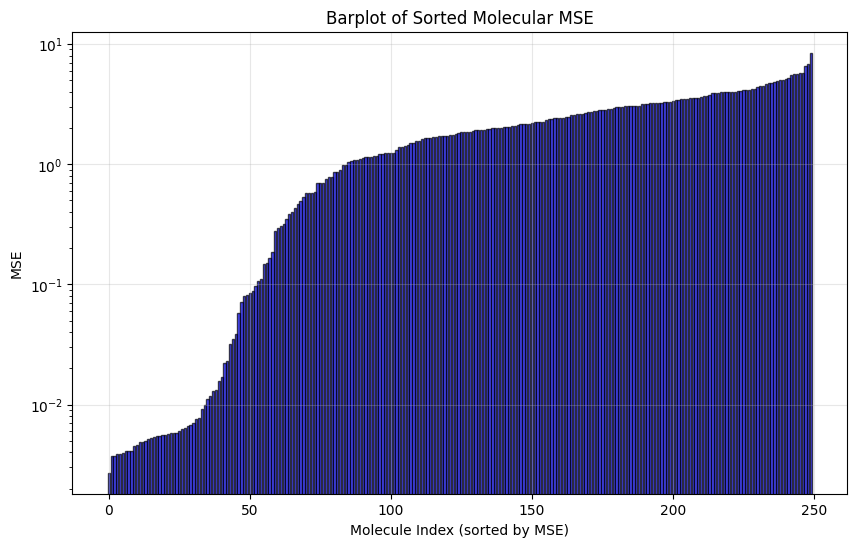

In [32]:
# Plot barplot of sorted mol_mse
plt.figure(figsize=(10, 6))
plt.bar(range(len(mol_mse)), sorted(mol_mse), color='blue', alpha=0.7, edgecolor='black')
plt.xlabel('Molecule Index (sorted by MSE)')
plt.ylabel('MSE')
plt.title('Barplot of Sorted Molecular MSE')
plt.grid(alpha=0.3)
plt.yscale('log')  # Use logarithmic scale for better visibility
plt.show()

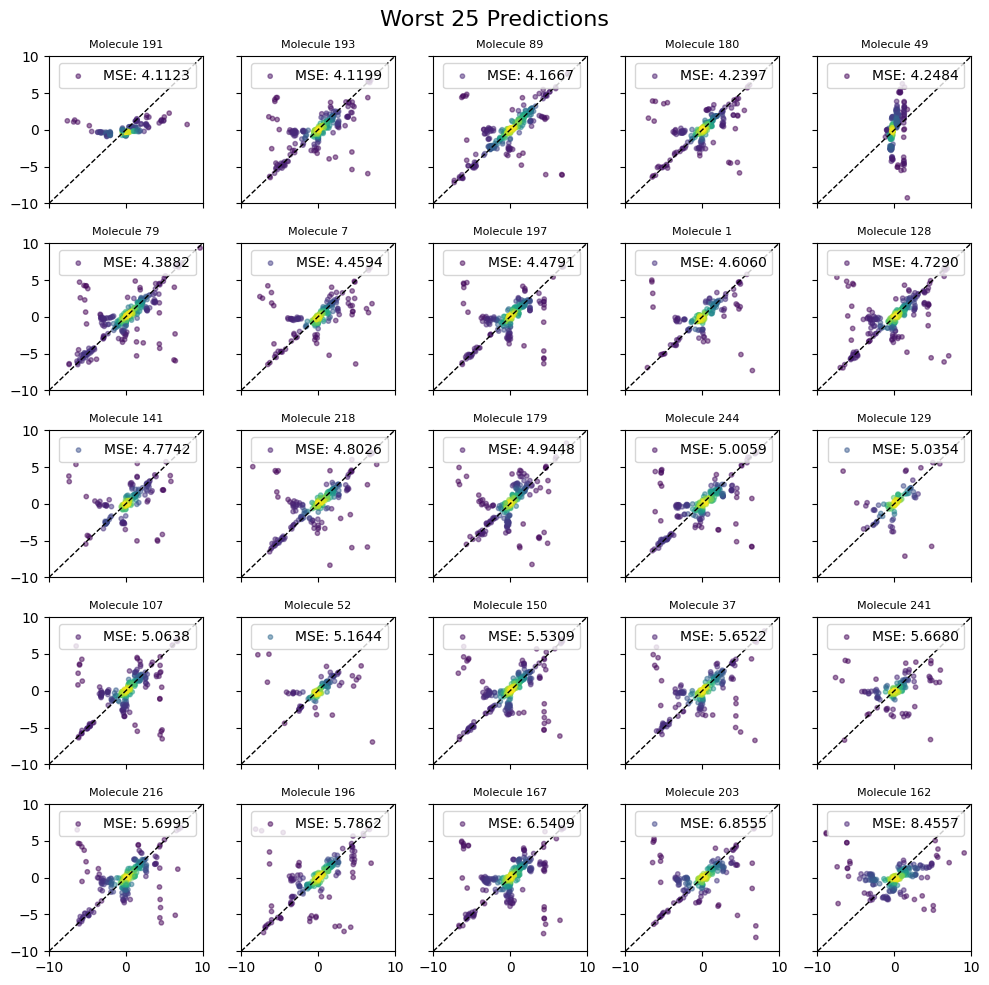

In [33]:
# Get indices of the top 25 mol_mse
top_25_indices = np.argsort(mol_mse)[-25:]

# Create a 5x5 grid of subplots
fig, axes = plt.subplots(nrows=5, ncols=5, figsize=(10, 10), sharex=True, sharey=True)
axes = axes.flatten()

# Plot each molecule's data in a separate subplot
for idx, mol_idx in enumerate(top_25_indices):
    ax = axes[idx]
    charges_target = mol_charges_target[mol_idx]
    charges_pred = mol_charges_pred[mol_idx]
    xy_filtered = np.vstack([charges_target, charges_pred])
    z_filtered = gaussian_kde(xy_filtered)(xy_filtered)
    ax.scatter(charges_target, charges_pred, s=10, alpha=0.5, c=z_filtered, cmap='viridis', label=f"MSE: {mol_mse[mol_idx]:.4f}")
    ax.plot([-10, 10], [-10, 10], 'k--', linewidth=1)  # Diagonal line
    ax.set_title(f'Molecule {mol_idx + 1}', fontsize=8)
    ax.legend(loc='upper right', fontsize=10)
    ax.set_xlim(-10, 10)
    ax.set_ylim(-10, 10)

# Remove unused subplots
for j in range(len(top_25_indices), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Worst 25 Predictions', fontsize=16)
plt.tight_layout()
plt.show()

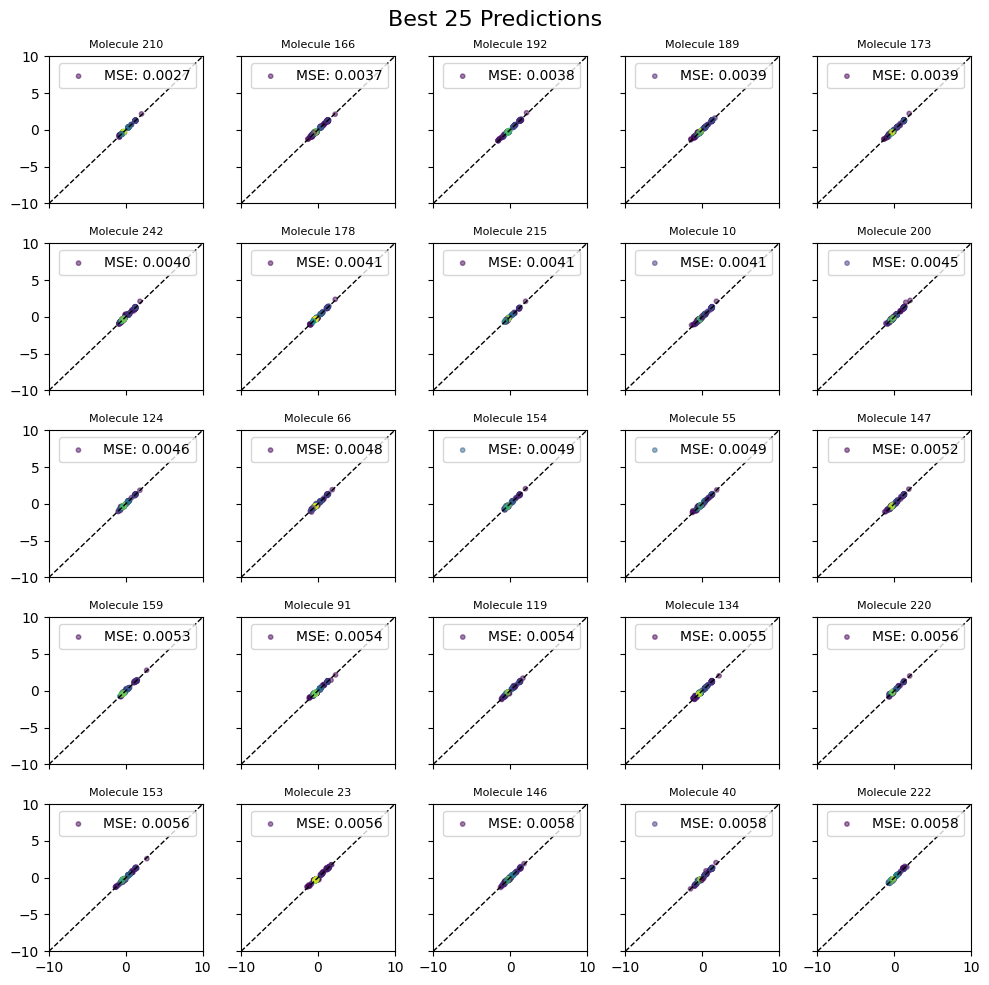

In [34]:
# Get indices of the top 25 mol_mse
top_25_indices = np.argsort(mol_mse)[:25]

# Create a 5x5 grid of subplots
fig, axes = plt.subplots(nrows=5, ncols=5, figsize=(10, 10), sharex=True, sharey=True)
axes = axes.flatten()

# Plot each molecule's data in a separate subplot
for idx, mol_idx in enumerate(top_25_indices):
    ax = axes[idx]
    charges_target = mol_charges_target[mol_idx]
    charges_pred = mol_charges_pred[mol_idx]
    xy_filtered = np.vstack([charges_target, charges_pred])
    z_filtered = gaussian_kde(xy_filtered)(xy_filtered)
    ax.scatter(charges_target, charges_pred, s=10, alpha=0.5, c=z_filtered, cmap='viridis', label=f"MSE: {mol_mse[mol_idx]:.4f}")
    ax.plot([-10, 10], [-10, 10], 'k--', linewidth=1)  # Diagonal line
    ax.set_title(f'Molecule {mol_idx + 1}', fontsize=8)
    ax.legend(loc='upper right', fontsize=10)
    ax.set_xlim(-10, 10)
    ax.set_ylim(-10, 10)

# Remove unused subplots
for j in range(len(top_25_indices), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Best 25 Predictions', fontsize=16)
plt.tight_layout()
plt.show()

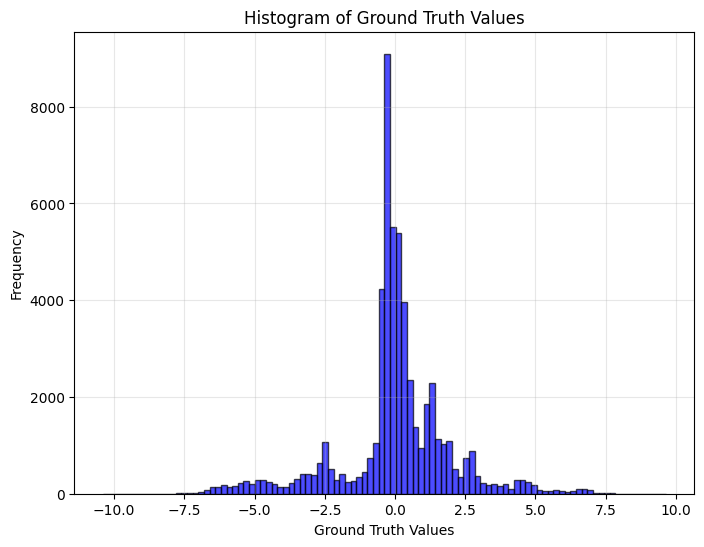

In [35]:
# Plot histogram of ground truth values
plt.figure(figsize=(8, 6))
plt.hist(outputs["ground_truth"], bins=100, color='blue', alpha=0.7, edgecolor='black')
plt.xlabel('Ground Truth Values')
plt.ylabel('Frequency')
plt.title('Histogram of Ground Truth Values')
plt.grid(alpha=0.3)
plt.show()

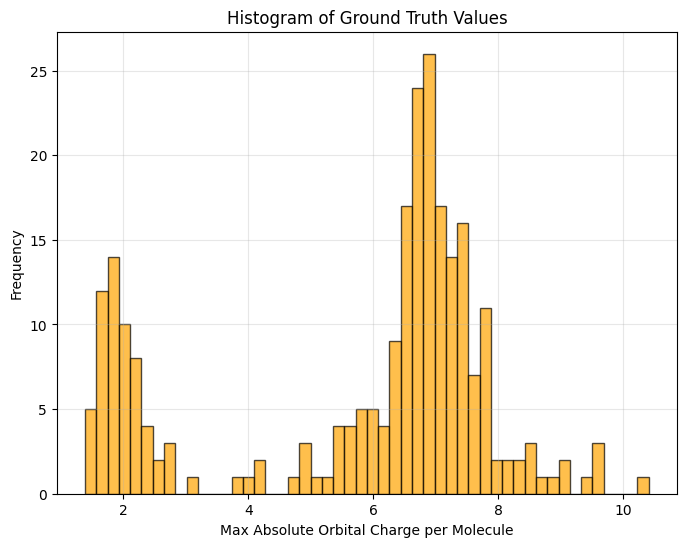

In [36]:
max_abs_charge_per_mol = [np.max(np.abs(mol)) for mol in mol_charges_target]
plt.figure(figsize=(8, 6))
plt.hist(max_abs_charge_per_mol, bins=50, color='orange', alpha=0.7, edgecolor='black')
plt.xlabel('Max Absolute Orbital Charge per Molecule')
plt.ylabel('Frequency')
plt.title('Histogram of Ground Truth Values')
plt.grid(alpha=0.3)
plt.show()

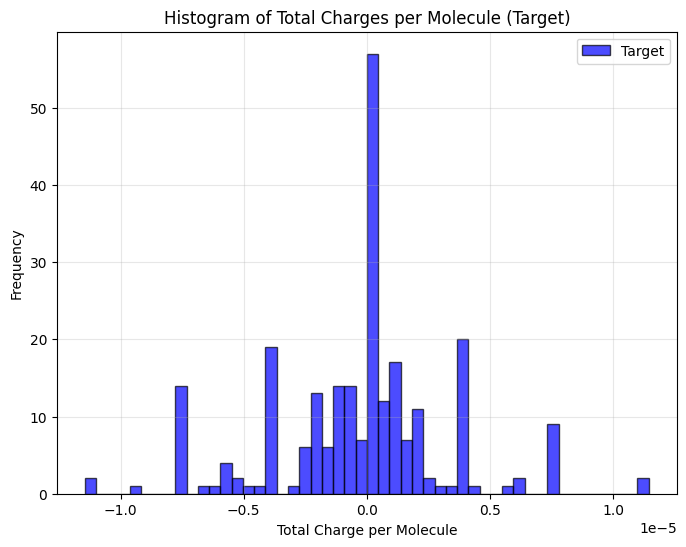

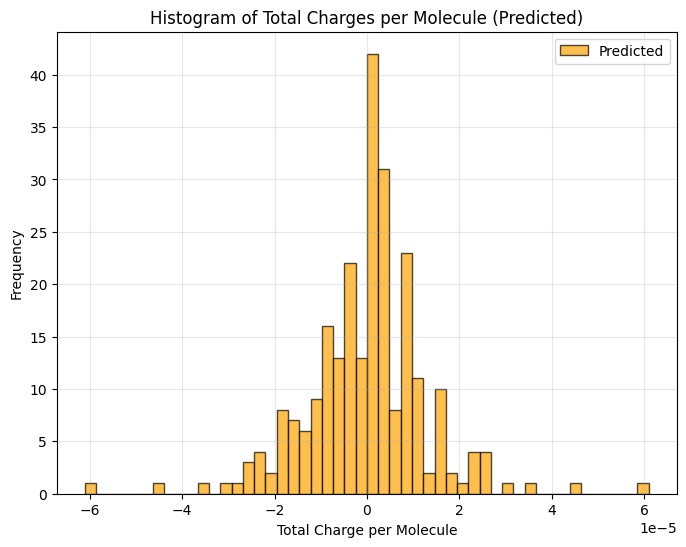

In [37]:
total_charge_per_mol = [np.sum(mol) for mol in mol_charges_target]
total_charge_per_mol_pred = [np.sum(mol) for mol in mol_charges_pred]
# Plot histogram of total charges per molecule (target)
plt.figure(figsize=(8, 6))
plt.hist(total_charge_per_mol, bins=50, color='blue', alpha=0.7, edgecolor='black', label='Target')
plt.xlabel('Total Charge per Molecule')
plt.ylabel('Frequency')
plt.title('Histogram of Total Charges per Molecule (Target)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Plot histogram of total charges per molecule (predicted)
plt.figure(figsize=(8, 6))
plt.hist(total_charge_per_mol_pred, bins=50, color='orange', alpha=0.7, edgecolor='black', label='Predicted')
plt.xlabel('Total Charge per Molecule')
plt.ylabel('Frequency')
plt.title('Histogram of Total Charges per Molecule (Predicted)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

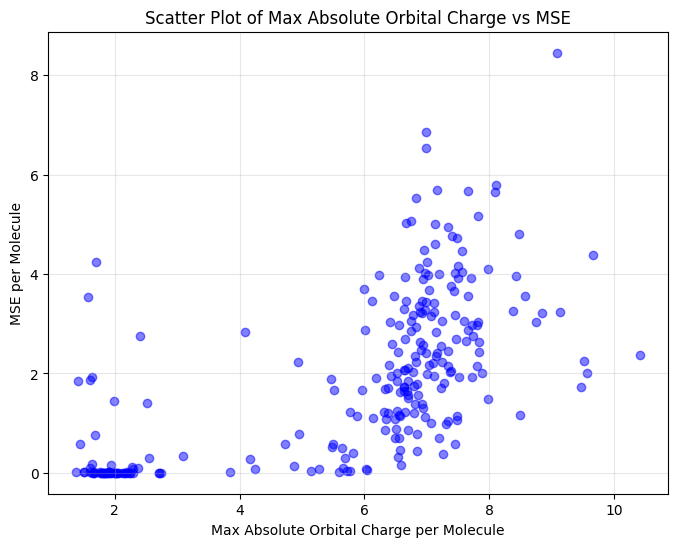

In [38]:
# Calculate max absolute charge per molecule
max_abs_charge_per_mol = [np.max(np.abs(mol)) for mol in mol_charges_target]

# Create the scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(max_abs_charge_per_mol, mol_mse, alpha=0.5, color='blue')
plt.xlabel('Max Absolute Orbital Charge per Molecule')
plt.ylabel('MSE per Molecule')
plt.title('Scatter Plot of Max Absolute Orbital Charge vs MSE')
plt.grid(alpha=0.3)
plt.show()

In [31]:
max_abs_charge_per_mol = np.array(max_abs_charge_per_mol)

In [34]:
max_abs_charge_per_mol[max_abs_charge_per_mol < 4].shape

(60,)

In [40]:
from ase import Atoms
import nglview as nv

In [41]:
np.argsort(mol_mse)[-25:]

array([190, 192,  88, 179,  48,  78,   6, 196,   0, 127, 140, 217, 178,
       243, 128, 106,  51, 149,  36, 240, 215, 195, 166, 202, 161])

In [47]:
mol_mse[161]

8.455674

In [42]:
from ase import Atoms
import nglview as nv
import numpy as np

In [48]:


# Create a simple ASE Atoms object
idx = 161
atoms = Atoms(
    numbers=mol_numbers[idx],  # Use the first molecule's atomic numbers
    positions=mol_positions[idx],  # Use the first molecule's positions
)

# Display the atoms using nglview
view = nv.show_ase(atoms)
view

NGLWidget()

In [51]:
# Save mol_numbers and mol_positions for the 10 worst molecules by MSE
worst_10_indices = np.argsort(mol_mse)[-10:]
for idx in worst_10_indices:
    np.savez(f"/home/ihor/projects/MLGuessQC/datasets/tmqm_worst_pred_debug/mol_{idx}_numbers_positions.npz", numbers=mol_numbers[idx], positions=mol_positions[idx])


In [67]:
# Save mol_numbers and mol_positions for the 10 best molecules by MSE
best_10_indices = np.argsort(mol_mse)[:10]
for idx in best_10_indices:
    np.savez(f"/home/ihor/projects/MLGuessQC/datasets/tmqm_best_pred_debug/mol_{idx}_numbers_positions.npz", numbers=mol_numbers[idx], positions=mol_positions[idx])


In [53]:
# Create a simple ASE Atoms object
idx = 36
atoms = Atoms(
    numbers=mol_numbers[idx],  # Use the first molecule's atomic numbers
    positions=mol_positions[idx],  # Use the first molecule's positions
)

# Display the atoms using nglview
view = nv.show_ase(atoms)
view

NGLWidget()

In [25]:
# Create a simple ASE Atoms object
idx = 88
atoms = Atoms(
    numbers=mol_numbers[idx],  # Use the first molecule's atomic numbers
    positions=mol_positions[idx],  # Use the first molecule's positions
)

# Display the atoms using nglview
view = nv.show_ase(atoms)
view

NGLWidget()

In [62]:
np.argsort(mol_mse)[:10]

array([209, 165, 191, 188, 172, 241, 177, 214,   9, 199])

In [65]:
mol_mse[165]

0.003714706

# Best

In [26]:
np.argsort(mol_mse)[:3]

array([209, 165, 191])

In [68]:
# Create a simple ASE Atoms object
idx = 209
atoms = Atoms(
    numbers=mol_numbers[idx],  # Use the first molecule's atomic numbers
    positions=mol_positions[idx],  # Use the first molecule's positions
)

# Display the atoms using nglview
view = nv.show_ase(atoms)
view

NGLWidget()

In [69]:
# Create a simple ASE Atoms object
idx = 165
atoms = Atoms(
    numbers=mol_numbers[idx],  # Use the first molecule's atomic numbers
    positions=mol_positions[idx],  # Use the first molecule's positions
)

# Display the atoms using nglview
view = nv.show_ase(atoms)
view

NGLWidget()

In [73]:
# Create a simple ASE Atoms object
idx = 199
atoms = Atoms(
    numbers=mol_numbers[idx],  # Use the first molecule's atomic numbers
    positions=mol_positions[idx],  # Use the first molecule's positions
)

# Display the atoms using nglview
view = nv.show_ase(atoms)
view

NGLWidget()